Distribution: Binomial
Parameters: n = 12 , p = 0.2
Possible values: [ 0  1  2  3  4  5  6  7  8  9 10 11 12]

Empirical vs Theoretical PMF:
 x  Empirical PMF  Theoretical PMF
 0         0.0686           0.0687
 1         0.2080           0.2062
 2         0.2796           0.2835
 3         0.2400           0.2362
 4         0.1308           0.1329
 5         0.0532           0.0532
 6         0.0152           0.0155
 7         0.0040           0.0033
 8         0.0006           0.0005
 9         0.0001           0.0001
10         0.0000           0.0000
11         0.0000           0.0000
12         0.0000           0.0000


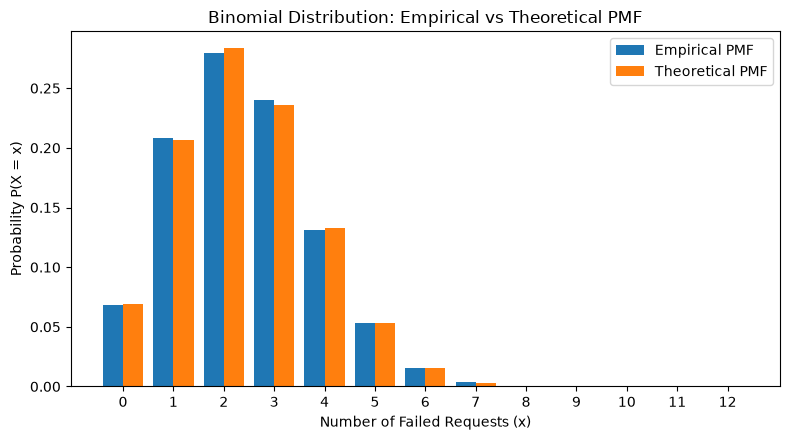


Expectation and Variance:
        Empirical  Theoretical
E[X]       2.4008         2.40
Var(X)     1.9310         1.92

Probability P(X >= 3):
Simulated probability = 0.4439
Theoretical probability = 0.4417


In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Given parameters
n = 12
p = 0.20
N = 20_000

# X = number of failed requests in one minute
rng = np.random.default_rng(42)
X = rng.binomial(n, p, size=N)

# (a) Identify distribution and possible values
x = np.arange(0, n + 1)

print("Distribution: Binomial")
print("Parameters: n =", n, ", p =", p)
print("Possible values:", x)

# (b) Empirical and theoretical PMF
emp = np.array([(X == k).mean() for k in x])
theo = stats.binom.pmf(x, n, p)

pmf_table = pd.DataFrame({
    "x": x,
    "Empirical PMF": emp,
    "Theoretical PMF": theo
})

print("\nEmpirical vs Theoretical PMF:")
print(pmf_table.round(4).to_string(index=False))

# (c) Plot both PMFs
plt.figure(figsize=(8, 4.5))

plt.bar(x - 0.2, emp, 0.4, label="Empirical PMF")
plt.bar(x + 0.2, theo, 0.4, label="Theoretical PMF")

plt.xlabel("Number of Failed Requests (x)")
plt.ylabel("Probability P(X = x)")
plt.title("Binomial Distribution: Empirical vs Theoretical PMF")
plt.xticks(x)
plt.legend()
plt.tight_layout()
plt.show()

# (d) Calculate expectation and variance
print("\nExpectation and Variance:")

print(pd.DataFrame({
    "Empirical": [X.mean(), X.var()],
    "Theoretical": [n * p, n * p * (1 - p)]
}, index=["E[X]", "Var(X)"]).round(4))

# (e) Calculate P(X >= 3)
p_sim = (X >= 3).mean()
p_theory = stats.binom.sf(2, n, p)

print("\nProbability P(X >= 3):")
print(f"Simulated probability = {p_sim:.4f}")
print(f"Theoretical probability = {p_theory:.4f}")